# ¿Se ve una locación desde el satélite, y cuándo?

Antes de perforar un pozo en Vaca Muerta se desmonta y se nivela una locación: un rectángulo de 100 a
200 metros en el monte de jarilla. Este notebook verifica que esa obra se ve en Sentinel-2 (gratis, 10 m,
cada 5 días) y que se puede fechar mes a mes, y mide cuánto antes aparece que el inicio de perforación y
la primera producción que registra la Secretaría de Energía.

Cinco áreas en cuatro ventanas, una escena limpia por mes de enero de 2020 a octubre de 2026. Nota: el
CBERS-4A, el satélite que usamos en otros laboratorios, no tiene ninguna escena sobre Neuquén en el
catálogo del INPE: su cobertura llega al centro del país.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from loclab import ZONAS, ANELO, CRS_METRICO, DATA_PROC, FIGURES
from loclab import escenas, padron, senal, ciego, figuras
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIGURES.mkdir(parents=True, exist_ok=True); DATA_PROC.mkdir(parents=True, exist_ok=True)

In [2]:
POZ = padron.pozos()
PROD = padron.primera_produccion()
POZ["produccion"] = POZ.idpozo.map(PROD)
print(f"pozos en el shapefile: {len(POZ)} · no convencionales con primera producción: {POZ.produccion.notna().sum()}")
pd.DataFrame({z: {"área": v["nombre"], "tile": v["tile"], "bbox": v["bbox"]} for z, v in ZONAS.items()}).T

pozos en el shapefile: 85797 · no convencionales con primera producción: 5126


,área,tile,bbox
loma_campana_oeste,Loma Campana oeste y Añelo,MGRS-19HET,"(-68.85, -38.4, -68.7, -38.28)"
norte_lac_bdp_bandurria,"La Amarga Chica, Bajada del Palo y Bandurria",MGRS-19HET,"(-68.75, -38.28, -68.52, -38.13)"
loma_campana_este,Loma Campana este,MGRS-19HET,"(-68.7, -38.42, -68.52, -38.28)"
fortin_de_piedra,Fortín de Piedra,MGRS-19HDT,"(-69.15, -38.57, -68.95, -38.43)"


## 1. La locación se ve, y el pozo cae encima

Loma Campana oeste en febrero de 2020 y en febrero de 2026, con las bocas de pozo del padrón. Las
coordenadas del Capítulo IV son de boca de pozo: en la zona, 710 de 770 pozos tienen otro a menos de
30 metros, que son las locaciones multipozo.

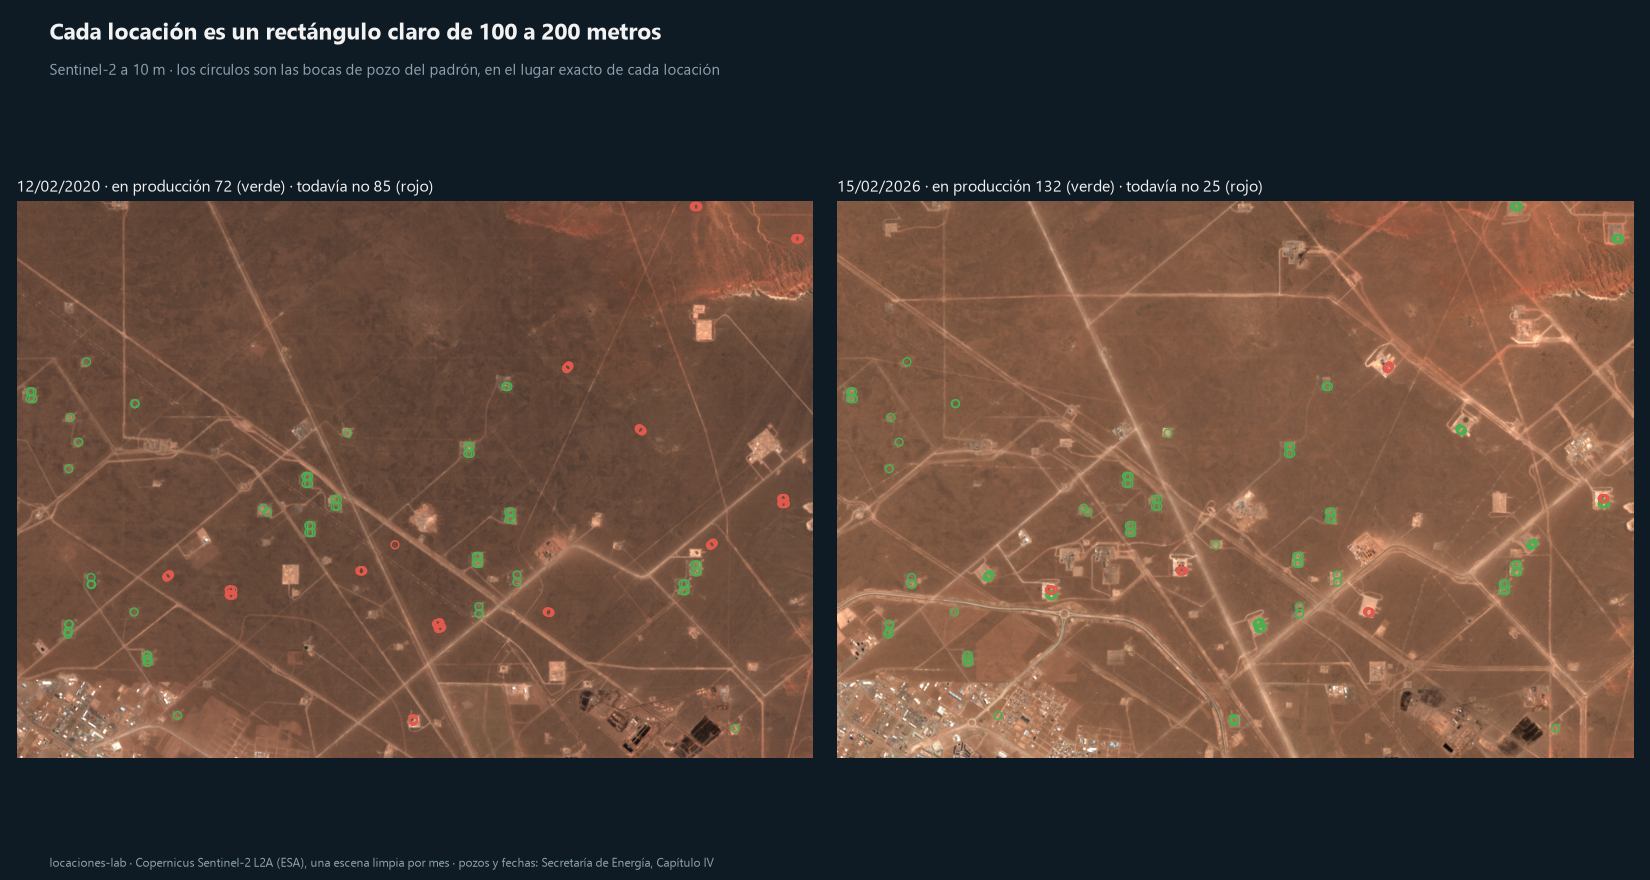

In [3]:
z = "loma_campana_oeste"
S = escenas.cargar_serie(z)
h, w = S["brillo"].shape[1:]
pz = padron.en_ventana(POZ[POZ.produccion.notna()], S["transform"], S["crs"], h, w)
i0, i1 = S["meses"].index("2020-02"), S["meses"].index("2026-02")
f0, f1 = pd.Timestamp(str(np.load(S["archivos"][i0])["fecha"])), pd.Timestamp(str(np.load(S["archivos"][i1])["fecha"]))
figuras.antes_despues(escenas.rgb(S["archivos"][i0]), escenas.rgb(S["archivos"][i1]), f0, f1, pz, FIGURES / "antes_despues.png", recorte=(0, 700, 300, 1300))
display(Image(FIGURES / "antes_despues.png"))

## 2. Cada locación del padrón, mes a mes

Para cada locación (pozos a menos de 30 m), el contraste contra el monte que la rodea en las 82 escenas.
La fecha de construcción sale a ciegas de la serie: el primer mes en que la locación se aclara y se
mantiene clara dos meses seguidos. Se evalúan las locaciones cuyo primer pozo empezó a perforarse
después de julio de 2020, para tener seis meses de base. Falsas alarmas: el mismo procedimiento en 500
puntos al azar de cada ventana, lejos de pozos y fuera del valle.

In [4]:
filas, falsas = [], {}
for z in ZONAS:
    S = escenas.cargar_serie(z)
    B, (h, w) = S["brillo"], S["brillo"].shape[1:]
    fechas = pd.to_datetime([m + "-15" for m in S["meses"]])
    pz = padron.en_ventana(POZ, S["transform"], S["crs"], h, w)
    L = padron.locaciones(pz, 10.0)
    for l in L.itertuples():
        s = senal.contraste(B, l.col, l.fila)
        if s is None:
            continue
        i = senal.mes_construccion(s)
        filas.append({"zona": z, "loc": l.loc, "pozos": l.pozos, "perforacion": l.perforacion, "produccion": l.produccion,
                      "detectada": fechas[i] if i is not None else pd.NaT, "serie": s, "fechas": fechas})
    e = np.load(S["archivos"][-1]); rng = np.random.default_rng(1); pts = []
    while len(pts) < 500:
        c, r = rng.uniform(40, w - 40), rng.uniform(40, h - 40)
        if e["green"][int(r), int(c)] >= e["red"][int(r), int(c)] or np.min(np.hypot(pz.col - c, pz.fila - r)) < 40:
            continue
        pts.append((c, r))
    falsas[z] = np.mean([senal.mes_construccion(senal.contraste(B, c, r)) is not None for c, r in pts])
    del B, S
R = pd.DataFrame(filas)
nuevas = R[R.perforacion > pd.Timestamp("2020-07-31")].copy()
nuevas["adelanto_perforacion"] = (nuevas.perforacion - nuevas.detectada).dt.days / 30.4
nuevas["adelanto_produccion"] = (nuevas.produccion - nuevas.detectada).dt.days / 30.4
det = nuevas.detectada.notna()
print(f"locaciones nuevas: {len(nuevas)} ({int(nuevas.pozos.sum())} pozos) · detectadas {det.sum()} ({100 * det.mean():.0f} %)")
print(f"adelanto sobre el inicio de perforación: mediana {nuevas.adelanto_perforacion.median():.1f} meses · la ve antes en el {100 * (nuevas.adelanto_perforacion > 0).mean():.0f} %")
print(f"adelanto sobre la primera producción: mediana {nuevas.adelanto_produccion.median():.1f} meses")
print("falsas alarmas por zona:", {k: f"{100 * v:.0f} %" for k, v in falsas.items()})
nuevas.drop(columns=["serie", "fechas"]).to_csv(DATA_PROC / "locaciones_fechadas.csv", index=False)
nuevas.groupby("zona").agg(locaciones=("loc", "size"), detectadas=("detectada", lambda s: s.notna().sum()),
                           adelanto_perforacion=("adelanto_perforacion", "median"), adelanto_produccion=("adelanto_produccion", "median")).round(1)

locaciones nuevas: 177 (725 pozos) · detectadas 167 (94 %)
adelanto sobre el inicio de perforación: mediana 2.3 meses · la ve antes en el 85 %
adelanto sobre la primera producción: mediana 9.5 meses
falsas alarmas por zona: {'loma_campana_oeste': '9 %', 'norte_lac_bdp_bandurria': '2 %', 'loma_campana_este': '2 %', 'fortin_de_piedra': '3 %'}


,locaciones,detectadas,adelanto_perforacion,adelanto_produccion
zona,,,,
fortin_de_piedra,29,25,3.2,11.1
loma_campana_este,48,45,1.6,10.5
loma_campana_oeste,23,23,4.0,14.5
norte_lac_bdp_bandurria,77,74,2.2,8.5


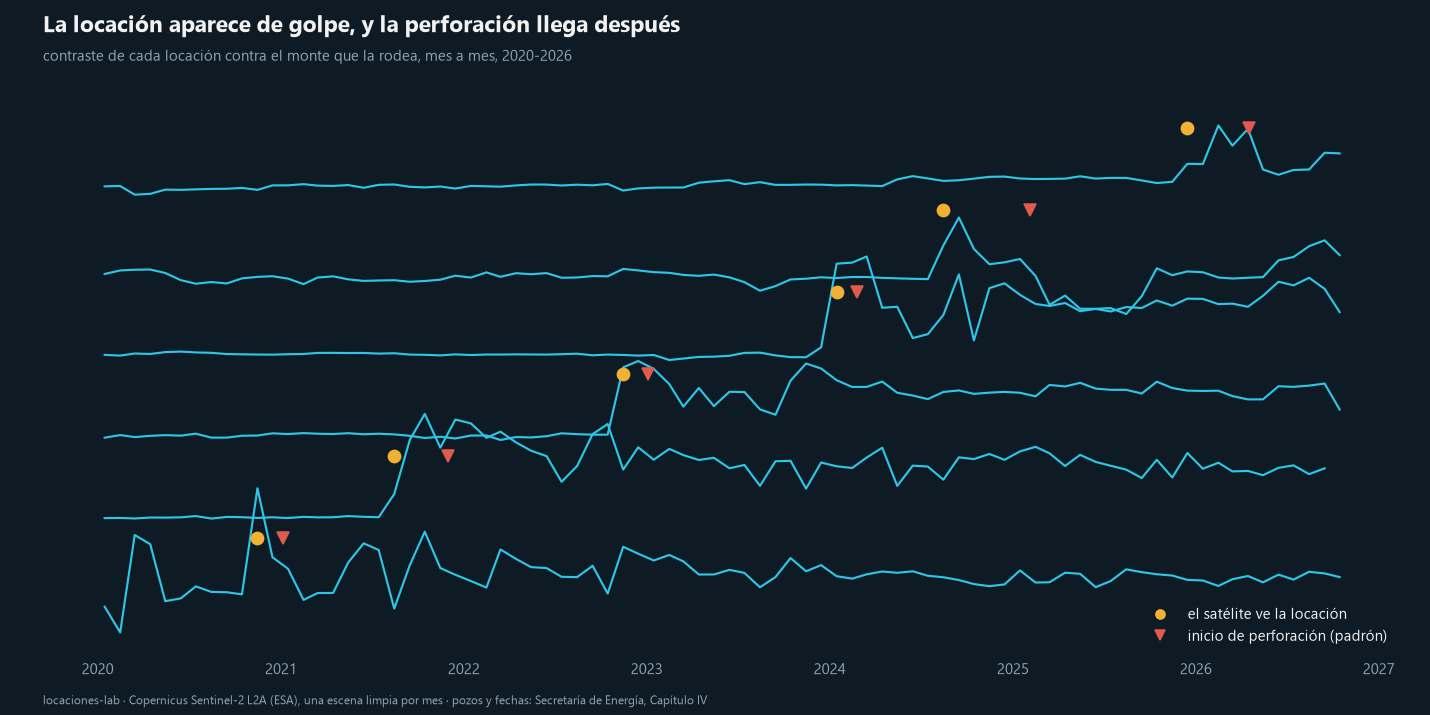

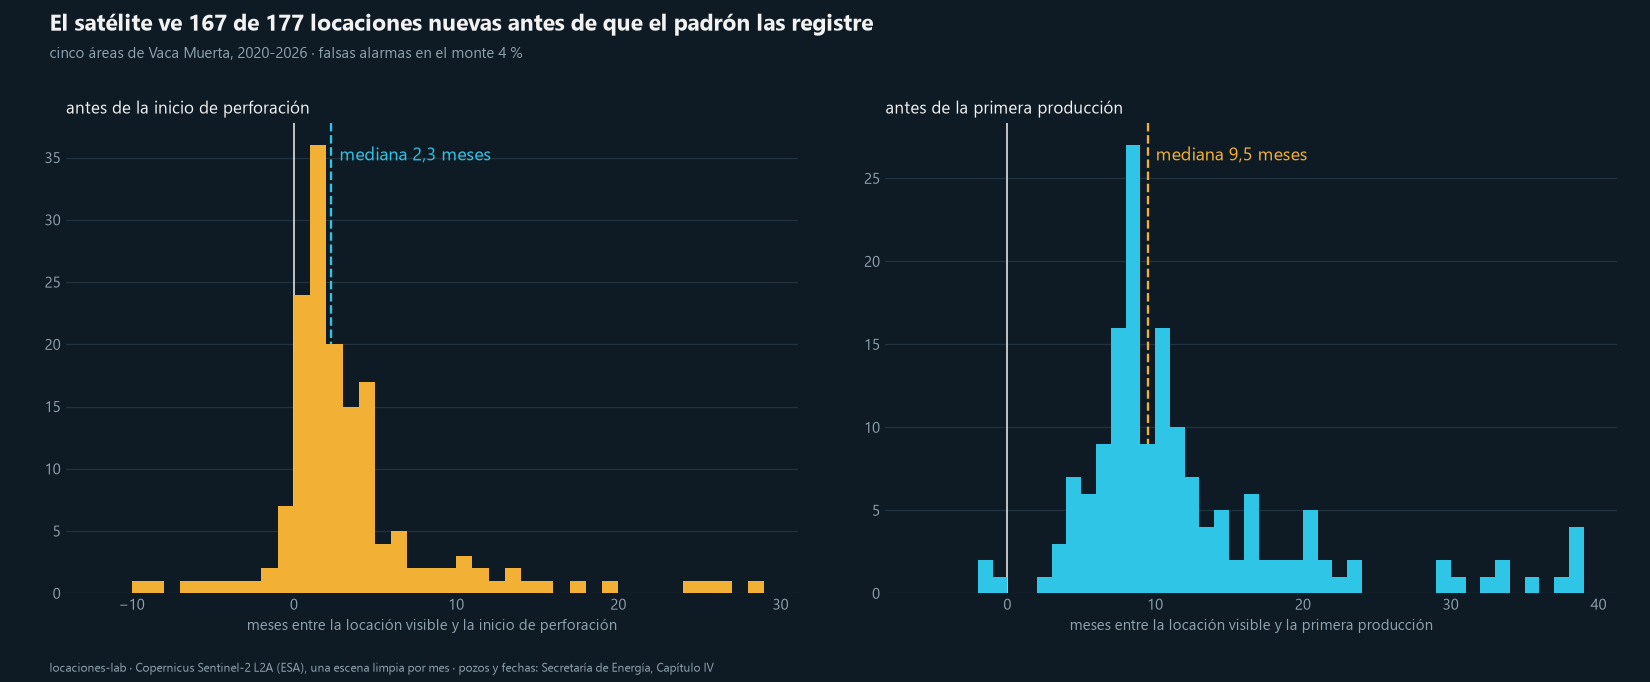

In [5]:
ej = nuevas[det & nuevas.produccion.notna() & nuevas.adelanto_perforacion.between(0.5, 12)].sort_values("perforacion")   # ejemplos típicos
ej = ej.iloc[np.linspace(0, len(ej) - 1, 6).astype(int)]
figuras.series_locaciones(ej.fechas.iloc[0], ej, FIGURES / "series_locaciones.png")
figuras.adelanto(nuevas.adelanto_perforacion.dropna(), nuevas.adelanto_produccion.dropna(), int(det.sum()), len(nuevas), float(np.mean(list(falsas.values()))), FIGURES / "adelanto.png")
display(Image(FIGURES / "series_locaciones.png")); display(Image(FIGURES / "adelanto.png"))

La locación aparece de golpe, con un pico de brillo que después decae, y la perforación llega
después. El satélite no adelanta mucho la perforación, porque el operador desmonta la locación poco
antes de traer el equipo. Lo que adelanta de verdad es la producción: casi un año antes de que el pozo
aparezca con su primer barril en el Capítulo IV, la locación ya se ve.